In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import extinction
from scipy.integrate import trapezoid

In [2]:
def gaussian_line(lam, center, flux, sigma):
    norm = flux / (sigma * np.sqrt(2 * np.pi))
    return norm * np.exp(-0.5 * ((lam - center) / sigma) ** 2)

In [3]:
def apply_extinction_odonnell(wave, spectrum, ebv,rv):
    
    av = rv * ebv
    a_lambda = extinction.odonnell94(wave, av, rv)
    attenuation_factor = 10 ** (-0.4 * a_lambda)

    return spectrum * attenuation_factor

In [4]:
def add_noise_by_halpha_flux(wave, spectrum, halpha_center, snr_halpha, window=20.0):
    mask = (wave > halpha_center - window) & (wave < halpha_center + window)
    n_pix = np.sum(mask)
    dl = np.median(np.diff(wave))

    # Halpha flux is approximately 1 before extinction/noise if normalized
    halpha_flux = trapezoid(spectrum[mask], wave[mask])

    # Desired integrated flux error
    flux_err_target = halpha_flux / snr_halpha

    # Convert integrated flux error to per-pixel noise std
    noise_std = flux_err_target / (np.sqrt(n_pix) * dl)

    noise = np.random.normal(0.0, noise_std, size=spectrum.shape)
    return spectrum + noise, noise_std

In [5]:
def sample_ngc253_ebv(size, mode="normal"):
    if mode == "fixed":
        return np.full(size, 0.36)

    if mode == "normal":
        ebv = np.random.normal(loc=0.36, scale=0.25, size=size)
        return np.clip(ebv, 0.0, 2.5)
        
    if mode == "lognorm":
        ebv = np.random.lognormal(mean=np.log(0.36), sigma=0.5, size=size)
        return np.clip(ebv, 0.0, 2.5)

In [6]:
def sample_velocity_shift(size):
    v_sys = 242.0
    v_local = np.random.uniform(-200.0, 200.0, size=size)
    return v_sys + v_local

In [7]:
def muse_sigma_v(wave_angstrom):
    
    c_kms = 299792.458
    wave = np.asarray(wave_angstrom, dtype=float)

    fwhm_angstrom = (5.866e-8 * wave**2 - 9.187e-4 * wave + 6.040)

    sigma_angstrom = fwhm_angstrom / 2.355
    sigma_v = c_kms * sigma_angstrom / wave

    return sigma_v

In [8]:
def sample_intrinsic_sigma_v(size, nebular_class):

    sigma_ranges = {"HII": (30.0, 50.0),
                    "PN":  (30.0, 50.0),
                    "DIG": (30.0, 50.0),
                    "SNR": (50.0, 150.0),}

    low, high = sigma_ranges[nebular_class]
    return np.random.uniform(low, high, size=size)

In [9]:
target_lines = {"H__1__4861A": 4861.33,
                "O__3__4959A": 4958.91,
                "O__3__5007A": 5006.84,
                "HE_1__5876A": 5875.62,
                "N__2__6548A": 6548.05,
                "H__1__6563A": 6562.80,
                "N__2__6584A": 6583.45,
                "S_II__6716A": 6716.44,
                "S_II__6731A": 6730.82,}

In [10]:
def mock_spectrum(row, wave, target_lines, sigma_intrinsic_v,  velocity_shift):
    c_kms = 299792.458
    spectrum = np.zeros_like(wave, dtype=float)

    for line_name, rest_wave in target_lines.items():
        line_flux = row[line_name]

        observed_center = rest_wave * (1.0 + velocity_shift / c_kms)
        
        sigma_muse_v_kms = muse_sigma_v(observed_center)
        sigma_total_v_kms = np.sqrt(sigma_muse_v_kms**2 + sigma_intrinsic_v**2)
        sigma_angstrom = observed_center * sigma_total_v_kms  / c_kms

        spectrum += gaussian_line(wave, observed_center, line_flux, sigma_angstrom)

    return spectrum

In [11]:
lam_min = 4600.0
lam_max = 9400.0
dl = 1.25

wave = np.arange(lam_min, lam_max + dl, dl)

In [13]:
models = pd.read_csv("models_constrained.csv")
print(models["class"].value_counts())

class
DIG    6545
HII     451
SNR     296
PN      216
Name: count, dtype: int64


In [14]:
spectra = []
labels = []
metadata = []


for idx, row in models.iterrows():
    neb_class = row["class"]

    ebv = sample_ngc253_ebv(1, "lognorm")[0]
    velocity_shift_kms = sample_velocity_shift(1)[0]

    sigma_intrinsic_v_kms = sample_intrinsic_sigma_v(1, nebular_class=neb_class)[0]

    spec = mock_spectrum(row, wave, target_lines, sigma_intrinsic_v_kms, velocity_shift_kms)

    spec = apply_extinction_odonnell(wave, spec, ebv, 3.1)

    halpha_center = target_lines["H__1__6563A"] * (1.0 + velocity_shift_kms / 299792.458)

    spec, noise_std = add_noise_by_halpha_flux(wave, spec, halpha_center, snr_halpha=100.0)

    if not np.all(np.isfinite(spec)):
        continue

    spectra.append(spec)
    labels.append(neb_class)

    metadata.append({
        "original_index": idx,
        "class": neb_class,
        "ebv": ebv,
        "velocity_shift_kms": velocity_shift_kms,
        "sigma_intrinsic_v_kms": sigma_intrinsic_v_kms,
        "snr_halpha": 100.0})

X = np.array(spectra)
Y = np.array(labels)
metadata = pd.DataFrame(metadata)

print(X.shape)
print(Y.shape)
print(metadata.head())

class_columns = ["HII", "PN", "SNR", "DIG"]
label_df = pd.DataFrame(0.0, index=np.arange(len(Y)), columns=class_columns)

for i, label in enumerate(Y):
    label_df.loc[i, label] = 1.0

mock_labels_metadata = pd.concat([metadata.reset_index(drop=True), label_df.reset_index(drop=True)],axis=1)
mock_labels_metadata.to_csv("mock_spectra_labels_metadata.csv", index=False)

print(mock_labels_metadata.head())

(7508, 3841)
(7508,)
   original_index class       ebv  velocity_shift_kms  sigma_intrinsic_v_kms  \
0               0   HII  0.626078          245.359189              49.746479   
1               1   HII  0.564890          137.783071              37.780485   
2               2   HII  0.729719          131.739500              41.182606   
3               3   HII  0.701758          185.247323              42.601632   
4               4   HII  0.452042          371.990958              36.874150   

   snr_halpha  
0       100.0  
1       100.0  
2       100.0  
3       100.0  
4       100.0  
   original_index class       ebv  velocity_shift_kms  sigma_intrinsic_v_kms  \
0               0   HII  0.626078          245.359189              49.746479   
1               1   HII  0.564890          137.783071              37.780485   
2               2   HII  0.729719          131.739500              41.182606   
3               3   HII  0.701758          185.247323              42.601632   
4 

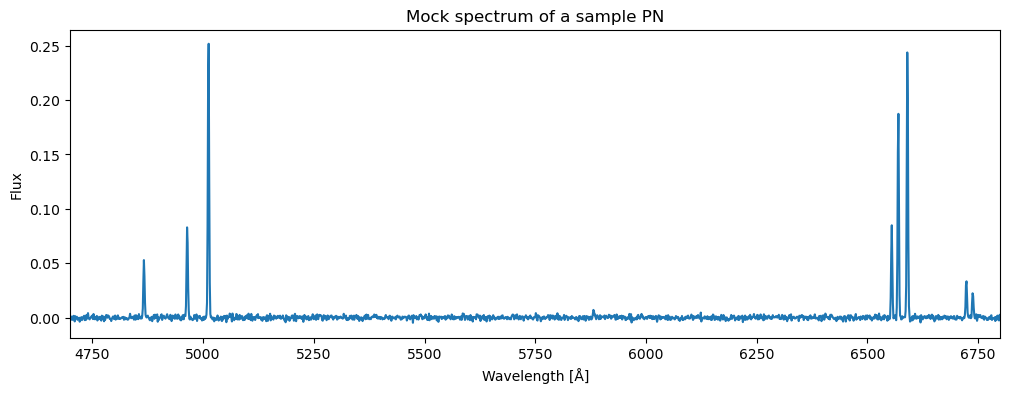

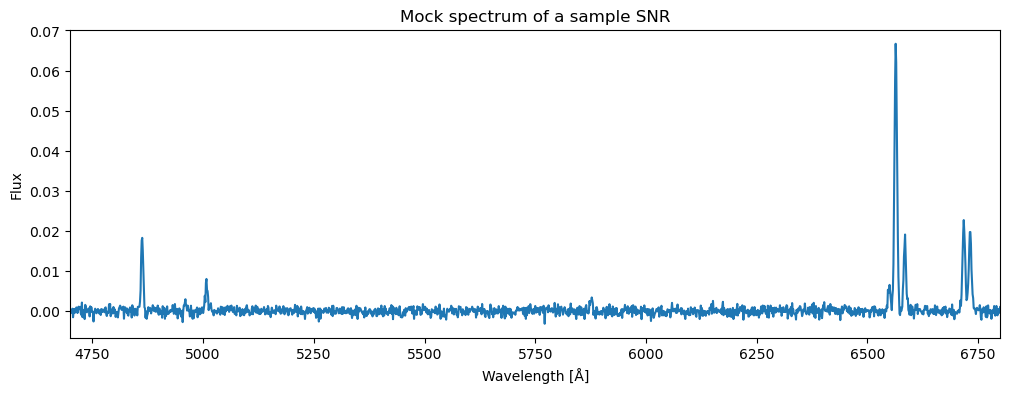

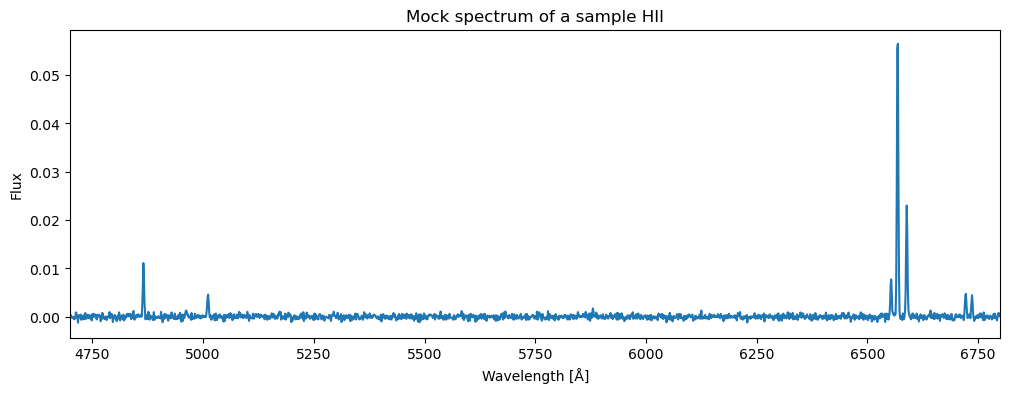

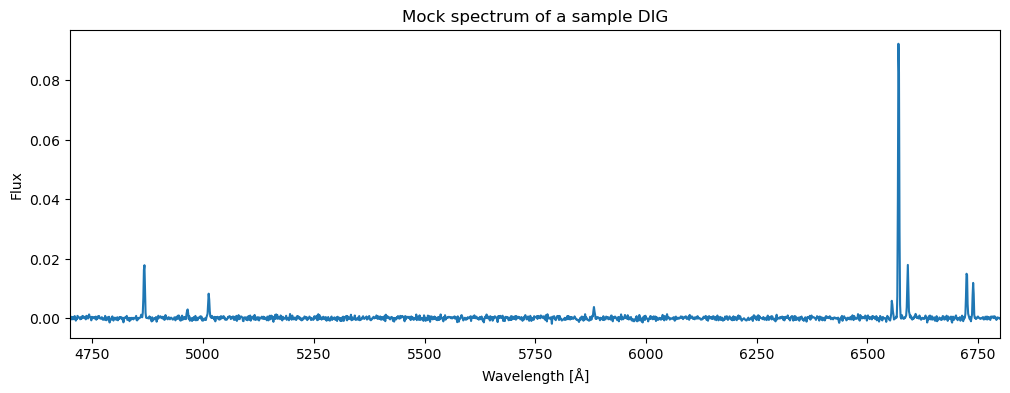

In [15]:
for target_class in ["PN", "SNR", "HII", "DIG"]:
    indices = np.where(Y == target_class)[0]
    i = indices[0]

    plt.figure(figsize=(12, 4))
    plt.plot(wave, X[i])
    plt.title(f"Mock spectrum of a sample {target_class}")
    plt.xlabel("Wavelength [Å]")
    plt.ylabel("Flux")
    plt.xlim(4700, 6800)
    plt.show()

In [16]:
np.save("mock_spectra.npy", X)
np.save("mock_wave.npy", wave)

metadata.to_csv("mock_spectra_metadata.csv", index=False)
mock_labels_metadata.to_csv("mock_spectra_labels_metadata.csv", index=False)